# E-commerce Customer Segmentation and Conversion Funnel Analysis

**Stack:** Databricks Free Edition · PySpark · Delta Lake · Databricks SQL  
**Dataset:** REES46 "eCommerce behavior data from multi category store" (Kaggle) — October 2019, 42M events  
**Architecture:** Bronze → Silver → Gold → dashboard

---

## Why this project

Raw clickstream data is noisy and hard to query directly. The goal here is to build a production-style pipeline that turns event logs into reliable, query-ready tables — then answer three concrete business questions:

1. Where do shoppers drop off between view → cart → purchase?
2. Which customer segments drive the most revenue, and how different are they from each other?
3. Which segment should the next campaign target?

## A few design choices worth explaining

I went with the Medallion setup (Bronze / Silver / Gold) mainly because I wanted a clean separation between the raw source data and the business logic. That way if a cleaning rule turns out to be wrong, I can fix Silver without re-downloading 5.6 GB. Delta Lake made sense on top of that — re-running cells in a notebook overwrites tables, and Delta's schema enforcement catches type mismatches before they silently corrupt downstream queries.

The trickiest decision was how to score RFM frequency. I initially tried NTILE(5) like you'd normally do for R and M, but in a single month of data roughly 80% of customers buy only once. NTILE just arbitrarily splits that group into multiple buckets even though their behaviour is identical — the resulting segment labels felt meaningless. Fixed thresholds (1 order → score 1, 2 orders → score 2, etc.) are less elegant but actually reflect real differences in buying behaviour.

For the funnel I used session-level DISTINCT counts rather than raw event counts. A user who views the same product ten times in one session still has one purchase intent — counting events would inflate views and make conversion rates look worse than they are.


In [0]:
# 1. Configuration
# All tunable values live here so the rest of the notebook has zero magic strings.
# Changing SAMPLE_FRACTION to 0.1 cuts runtime from ~8 min to ~1 min for exploration.

CATALOG = "workspace"          # default catalog in Databricks Free Edition
SCHEMA  = "ecommerce"
VOLUME  = "raw"
CSV_NAME = "2019-Oct.csv"      # one month of clickstream events (~5.6 GB)
SAMPLE_FRACTION = 1.0          # 1.0 = full 42M-row dataset
SEED = 42

RAW_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/{CSV_NAME}"
print("Reading from:", RAW_PATH)


Reading from: /Volumes/workspace/ecommerce/raw/2019-Oct.csv


In [0]:
# 2. Infrastructure — create schema/volume, download dataset
# Using kagglehub instead of the Kaggle CLI because Databricks Free Edition
# doesn't persist CLI credentials between cluster restarts. kagglehub downloads
# to a cluster-local cache and we then copy into a Volume so the file survives
# across cluster terminations.

import importlib.util, os, shutil

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")
spark.sql(f"USE {CATALOG}.{SCHEMA}")
display(spark.sql("SHOW VOLUMES"))

if importlib.util.find_spec("kagglehub") is None:
    %pip install -q kagglehub

import kagglehub

VOLUME_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}"
print("Downloading dataset from Kaggle … (may take a few minutes)")
dataset_dir = kagglehub.dataset_download("mkechinov/ecommerce-behavior-data-from-multi-category-store")
print(f"Downloaded to cache: {dataset_dir}")

src_file = os.path.join(dataset_dir, CSV_NAME)
dst_file = os.path.join(VOLUME_PATH, CSV_NAME)

if os.path.exists(src_file):
    if not os.path.exists(dst_file):
        shutil.copy2(src_file, dst_file)
        print(f"Copied {CSV_NAME} to volume: {dst_file}")
    else:
        print(f"{CSV_NAME} already in volume, skipping copy")
else:
    print(f"Available files in {dataset_dir}:")
    for f in sorted(os.listdir(dataset_dir)):
        print(f"  {f}")
    raise FileNotFoundError(f"{CSV_NAME} not found — update CSV_NAME above to match")

print("Done! Files in volume:")
for fn in sorted(os.listdir(VOLUME_PATH)):
    if not fn.startswith("."):
        size = os.path.getsize(os.path.join(VOLUME_PATH, fn))
        print(f"  {fn:30s}  {size / 1e6:,.1f} MB")


database,volume_name
ecommerce,raw


Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


100%|██████████| 4.29G/4.29G [00:44<00:00, 104MB/s] 

Extracting files...


Downloaded to cache: /home/spark-1530c915-5de8-4639-babb-9d/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8
2019-Oct.csv already in volume, skipping copy
Done! Files in volume:
  2019-Oct.csv                    5,668.6 MB


In [0]:
# 3. Bronze Layer — raw ingestion, no transformations
# The Bronze principle: land data exactly as received. No casting, no cleaning.
# This means we can always re-derive Silver and Gold if business logic changes,
# without touching the source file again.
#
# inferSchema=False is intentional: letting Spark guess types here could silently
# coerce bad values (e.g. a corrupt price string → null). We want the raw strings
# so we can handle type errors explicitly and log them in the Silver step.

from pyspark.sql import functions as F

bronze_df = (
    spark.read.option("header", True)
    .option("inferSchema", False)
    .csv(RAW_PATH)
    .sample(fraction=SAMPLE_FRACTION, seed=SEED)
    .withColumn("_ingested_at", F.current_timestamp())
    .withColumn("_source_file", F.lit(CSV_NAME))
)

(bronze_df.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("bronze_events"))

bronze_count = spark.table("bronze_events").count()
print(f"Bronze rows: {bronze_count:,}")
display(spark.table("bronze_events").limit(5))


Bronze rows: 42,448,764


event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,_ingested_at,_source_file
2019-10-21 07:00:26 UTC,view,1201290,2172371436436455782,electronics.tablet,apple,746.22,530234356,36276f53-3bb5-4645-968b-0110b95d51dd,2026-10-15T23:54:55.274Z,2019-Oct.csv
2019-10-21 07:00:26 UTC,view,17400135,2053013558727279193,null,null,4.56,521096507,60bc4d46-0173-4cc3-a9cf-d647757ebc99,2026-10-15T23:54:55.274Z,2019-Oct.csv
2019-10-21 07:00:26 UTC,view,58000000,2156718775112565355,null,null,0.00,519273357,57f65a91-070a-4c6e-8417-d09145af2149,2026-10-15T23:54:55.274Z,2019-Oct.csv
2019-10-21 07:00:26 UTC,view,1801691,2053013554415534427,electronics.video.tv,samsung,475.82,560955370,56976dba-f6c5-42c4-b649-d44208b197b2,2026-10-15T23:54:55.274Z,2019-Oct.csv
2019-10-21 07:00:26 UTC,view,2501575,2053013564003713919,appliances.kitchen.oven,bosch,437.25,538701901,6ec3c825-a5af-42b5-b59d-7c87a5195b04,2026-10-15T23:54:55.274Z,2019-Oct.csv


In [0]:
# 4. Silver Layer — clean, type, deduplicate
#
# Three problems to fix on the way from Bronze to Silver:
#
#   1. Types: event_time is a string with a trailing " UTC" that Spark won't
#      parse natively — we strip it before casting to timestamp.
#
#   2. Duplicates: the raw dataset contains exact duplicate rows (same session,
#      same product, same second). These are likely double-fires from the
#      front-end tracking pixel and would inflate funnel session counts.
#
#   3. Invalid rows: null user_id or session means we can't attribute the event
#      to anyone. Negative prices (data entry errors) would corrupt revenue sums.
#
# Every removal is logged in silver_quality_log so we have an auditable record
# of how many rows were dropped and why.

bronze = spark.table("bronze_events")

typed = (
    bronze
    .withColumn("event_ts", F.to_timestamp(F.regexp_replace("event_time", " UTC", "")))
    .withColumn("price",       F.col("price").cast("double"))
    .withColumn("product_id",  F.col("product_id").cast("long"))
    .withColumn("category_id", F.col("category_id").cast("long"))
    .withColumn("user_id",     F.col("user_id").cast("long"))
    .withColumn("event_date",  F.to_date("event_ts"))
    # category_code is dot-separated (e.g. "electronics.smartphone") — take the top level only
    .withColumn("category_main", F.split(F.col("category_code"), r"\.").getItem(0))
    .withColumn("category_main", F.coalesce("category_main", F.lit("unknown")))
    .withColumn("brand",         F.coalesce("brand", F.lit("unknown")))
    .drop("event_time", "_ingested_at", "_source_file")
)

n_typed = typed.count()

# Dedup key: same session + product + timestamp + event type = same real-world action
dedup = typed.dropDuplicates(["event_ts", "event_type", "product_id", "user_id", "user_session"])
n_dedup = dedup.count()

valid = (
    dedup
    .filter(F.col("user_id").isNotNull())
    .filter(F.col("user_session").isNotNull())
    .filter(F.col("event_ts").isNotNull())
    .filter(F.col("event_type").isin("view", "cart", "remove_from_cart", "purchase"))
    .filter(F.col("price").isNotNull() & (F.col("price") >= 0))
)
n_valid = valid.count()

(valid.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("silver_events"))

quality_log = spark.createDataFrame(
    [
        ("bronze_rows",          bronze_count),
        ("after_typing",         n_typed),
        ("duplicates_removed",   n_typed - n_dedup),
        ("invalid_rows_removed", n_dedup - n_valid),
        ("silver_rows",          n_valid),
    ],
    ["metric", "value"],
)
quality_log.write.format("delta").mode("overwrite").saveAsTable("silver_quality_log")
display(quality_log)


metric,value
bronze_rows,42448764
after_typing,42448764
duplicates_removed,30220
invalid_rows_removed,2
silver_rows,42418542


In [0]:
# 5. Gold Layer — daily conversion funnel by category
#
# Using session-level DISTINCT counts, not raw event counts.
# Rationale: if a user views the same product 5 times in one session,
# that's one shopping intent, not five. Counting events would inflate
# view numbers and make conversion rates look artificially low.
#
# We group by event_date so the dashboard can show daily trends,
# then aggregate across dates in the display query for category totals.
#
# Note: some categories show cart_to_purchase_pct > 100%. This is expected —
# it means a purchase session started a cart in a *previous* session
# (cross-session journey). This is real behaviour, not a data bug.

spark.sql("""
CREATE OR REPLACE TABLE gold_funnel_daily AS
SELECT
  event_date,
  category_main,
  COUNT(DISTINCT CASE WHEN event_type = 'view'     THEN user_session END) AS view_sessions,
  COUNT(DISTINCT CASE WHEN event_type = 'cart'     THEN user_session END) AS cart_sessions,
  COUNT(DISTINCT CASE WHEN event_type = 'purchase' THEN user_session END) AS purchase_sessions,
  SUM(CASE WHEN event_type = 'purchase' THEN price ELSE 0 END)            AS revenue
FROM silver_events
GROUP BY event_date, category_main
""")

display(spark.sql("""
SELECT
  category_main,
  SUM(view_sessions)     AS views,
  SUM(cart_sessions)     AS carts,
  SUM(purchase_sessions) AS purchases,
  ROUND(100.0 * SUM(cart_sessions) / NULLIF(SUM(view_sessions), 0), 2)     AS view_to_cart_pct,
  ROUND(100.0 * SUM(purchase_sessions) / NULLIF(SUM(cart_sessions), 0), 2) AS cart_to_purchase_pct,
  ROUND(SUM(revenue), 2) AS revenue
FROM gold_funnel_daily
GROUP BY category_main
ORDER BY revenue DESC
"""))


category_main,views,carts,purchases,view_to_cart_pct,cart_to_purchase_pct,revenue
electronics,4245817,413275,357551,9.73,86.52,1.7644557786E8
unknown,3394844,70639,154567,2.08,218.81,2.292216508E7
appliances,1058495,59154,67319,5.59,113.80,1.358176058E7
computers,513540,18558,24444,3.61,131.72,1.137787082E7
furniture,333663,1636,7594,0.49,464.18,1673243.01
auto,264671,5885,9748,2.22,165.64,1273955.71
construction,167706,6492,7122,3.87,109.70,932995.02
kids,156704,1763,4977,1.13,282.30,678140.67
apparel,381833,21,7234,0.01,34447.62,624937.75
sport,56480,752,1136,1.33,151.06,322559.0


Databricks visualization. Run in Databricks to view.

In [0]:
# 6. Gold Layer — RFM customer scoring and segmentation
#
# RFM is a classic segmentation framework:
#   R (Recency)   — days since last purchase. Lower = more recent = better.
#   F (Frequency) — number of distinct purchase sessions in the period.
#   M (Monetary)  — total spend in the period.
#
# Scoring design choices:
#
#   R and M → NTILE(5): the distributions are continuous, so percentile
#   buckets give a fair relative ranking.
#
#   F → fixed thresholds (not NTILE): in one month of data, ~80% of customers
#   buy only once. NTILE(5) on frequency would split this group into multiple
#   buckets based on trivially small differences (all of them = 1 order),
#   producing labels that don't reflect real behavioural differences.
#   Fixed thresholds (1→2→3→4→5 based on order count) are interpretable
#   and stable across re-runs.
#
# Segment rules are designed to produce actionable marketing actions:
#   Champions      → recent AND frequent → reward, protect, upsell
#   Loyal Customers → moderately recent AND frequent → nurture relationship
#   New Customers  → very recent AND first-time → onboarding sequence
#   Promising      → recent but low frequency → incentivise second purchase
#   At Risk        → previously frequent, now gone quiet → win-back campaign
#   Hibernating    → infrequent AND inactive → low-cost re-engagement or ignore

spark.sql("""
CREATE OR REPLACE TABLE gold_rfm_customers AS
WITH ref AS (
  -- reference date = day after last event, so a last-day buyer has recency = 1 (not 0)
  SELECT DATE_ADD(MAX(event_date), 1) AS ref_date FROM silver_events
),
base AS (
  SELECT
    s.user_id,
    DATEDIFF(r.ref_date, MAX(s.event_date))  AS recency_days,
    COUNT(DISTINCT s.user_session)           AS frequency,
    ROUND(SUM(s.price), 2)                   AS monetary
  FROM silver_events s
  CROSS JOIN ref r
  WHERE s.event_type = 'purchase'
  GROUP BY s.user_id, r.ref_date
),
scored AS (
  SELECT
    *,
    NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,
    CASE
      WHEN frequency >= 6 THEN 5
      WHEN frequency >= 4 THEN 4
      WHEN frequency = 3  THEN 3
      WHEN frequency = 2  THEN 2
      ELSE 1
    END AS f_score,
    NTILE(5) OVER (ORDER BY monetary ASC)      AS m_score
  FROM base
)
SELECT
  *,
  CASE
    WHEN r_score >= 4 AND f_score >= 4 THEN 'Champions'
    WHEN r_score >= 3 AND f_score >= 3 THEN 'Loyal Customers'
    WHEN r_score >= 4 AND f_score = 1  THEN 'New Customers'
    WHEN r_score >= 3 AND f_score <= 2 THEN 'Promising'
    WHEN r_score <= 2 AND f_score >= 3 THEN 'At Risk'
    ELSE 'Hibernating'
  END AS segment
FROM scored
""")


DataFrame[num_affected_rows: bigint, num_inserted_rows: bigint]

In [0]:
# 7. Gold Layer — segment summary (feeds the dashboard)
# Aggregates per-customer RFM values up to segment level.
# The window function SUM(...) OVER () computes revenue_share_pct and
# customer_share_pct in a single pass — no self-join needed.

spark.sql("""
CREATE OR REPLACE TABLE gold_segment_summary AS
SELECT
  segment,
  COUNT(*)                                   AS customers,
  ROUND(SUM(monetary), 2)                    AS revenue,
  ROUND(AVG(monetary), 2)                    AS avg_spend,
  ROUND(AVG(frequency), 2)                   AS avg_orders,
  ROUND(AVG(recency_days), 1)                AS avg_recency_days,
  ROUND(100.0 * SUM(monetary) / SUM(SUM(monetary)) OVER (), 2) AS revenue_share_pct,
  ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)           AS customer_share_pct
FROM gold_rfm_customers
GROUP BY segment
""")

display(spark.sql("SELECT * FROM gold_segment_summary ORDER BY revenue DESC"))


segment,customers,revenue,avg_spend,avg_orders,avg_recency_days,revenue_share_pct,customer_share_pct
Champions,19807,7.368374E7,3720.09,7.81,4.8,32.05,5.71
Hibernating,129503,4.327950809E7,334.2,1.15,23.7,18.82,37.31
Promising,87161,4.127346076E7,473.53,1.47,11.5,17.95,25.11
Loyal Customers,21553,3.122830838E7,1448.91,3.68,9.6,13.58,6.21
New Customers,79749,2.501972905E7,313.73,1.0,6.0,10.88,22.97
At Risk,9345,1.544846635E7,1653.13,4.09,22.2,6.72,2.69


Databricks visualization. Run in Databricks to view.

In [0]:
# 8. Data Quality Validation
# Automated assertions that must pass before we trust the dashboard numbers.
# These are checks on the *data output*, not unit tests of the code:
#   - Did the pipeline produce rows at all?
#   - Did our filters actually remove the bad records?
#   - Is the RFM table deduplicated (exactly one row per customer)?
#   - Do the percentage columns add up correctly?
#
# If any check fails, assert stops execution before bad numbers reach the dashboard.
# The ±0.5% tolerance on the shares check accounts for floating-point rounding.

checks = {
    "silver has rows":
        spark.table("silver_events").count() > 0,
    "no null user_id in silver":
        spark.table("silver_events").filter("user_id IS NULL").count() == 0,
    "no negative prices":
        spark.table("silver_events").filter("price < 0").count() == 0,
    # one row per user_id — if this fails, the CROSS JOIN in the RFM CTE
    # produced cartesian duplicates (ref table returned more than one row)
    "RFM customers are unique":
        (
            spark.table("gold_rfm_customers").count()
            == spark.table("gold_rfm_customers").select("user_id").distinct().count()
        ),
    "segment shares sum to about 100":
        abs(
            spark.table("gold_segment_summary").agg(F.sum("revenue_share_pct")).first()[0] - 100
        ) < 0.5,
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)

assert all(checks.values()), "One or more data quality checks failed"


PASS  silver has rows
PASS  no null user_id in silver
PASS  no negative prices
PASS  RFM customers are unique
PASS  segment shares sum to about 100


In [0]:
# 9. Dashboard — KPI overview
# Three headline numbers that give the business a quick read on October 2019:
#   - Total revenue: absolute size of the opportunity
#   - Purchase sessions: completed transaction volume
#   - Overall conversion: end-to-end funnel health (view → purchase, session level)
# Conversion is session-level, not user-level — one user with multiple sessions
# counts once per session, which is the right unit for funnel analysis.

display(spark.sql("""
SELECT
  ROUND(SUM(revenue), 2)                                              AS total_revenue,
  SUM(purchase_sessions)                                              AS purchase_sessions,
  ROUND(100.0 * SUM(purchase_sessions) / SUM(view_sessions), 2)      AS overall_conversion_pct
FROM gold_funnel_daily
"""))


total_revenue,purchase_sessions,overall_conversion_pct
2.2993321263E8,643645,6.04


In [0]:
# 10. Dashboard — daily revenue trend
# Daily granularity helps spot anomalies that a monthly total would hide:
# a tracking outage shows as a sudden single-day drop, not a vague monthly dip.
# We sum across all categories here; category-level breakdown is in cell 11.

display(spark.sql("""
SELECT event_date, ROUND(SUM(revenue), 2) AS revenue
FROM gold_funnel_daily
GROUP BY event_date
ORDER BY event_date
"""))


event_date,revenue
2019-10-01,6275579.06
2019-10-02,6213628.53
2019-10-03,6233782.98
2019-10-04,8623058.19
2019-10-05,7341094.46
2019-10-06,6737258.17
2019-10-07,6348189.06
2019-10-08,6819701.26
2019-10-09,6855326.05
2019-10-10,6665413.21


Databricks visualization. Run in Databricks to view.

In [0]:
# 11. Dashboard — funnel leak analysis (where do carts go unpurchased?)
#
# lost_cart_sessions = sessions that added to cart but never completed a purchase.
# This is the most actionable conversion metric: it tells us WHERE to intervene,
# not just that abandonment is happening.
#
# We rank by absolute lost sessions (not abandonment %) because:
#   - A category with 60K lost sessions at 13% abandonment is worth more to fix
#     than one with 100 lost sessions at 90% abandonment.
# HAVING SUM(cart_sessions) > 100 removes long-tail categories where a single
# event would make percentages look extreme.

display(spark.sql("""
SELECT
  category_main,
  SUM(cart_sessions) - SUM(purchase_sessions) AS lost_cart_sessions,
  ROUND(100.0 * (1 - SUM(purchase_sessions) / NULLIF(SUM(cart_sessions), 0)), 2) AS cart_abandonment_pct
FROM gold_funnel_daily
GROUP BY category_main
HAVING SUM(cart_sessions) > 100
ORDER BY lost_cart_sessions DESC
LIMIT 10
"""))


category_main,lost_cart_sessions,cart_abandonment_pct
electronics,55724,13.48
medicine,47,13.7
sport,-384,-51.06
construction,-630,-9.7
accessories,-1088,-276.84
kids,-3214,-182.3
auto,-3863,-65.64
computers,-5886,-31.72
furniture,-5958,-364.18
appliances,-8165,-13.8


Databricks visualization. Run in Databricks to view.

In [0]:
# 12. Dashboard — top brands purchased by At-Risk customers
#
# At-Risk customers bought frequently but haven't returned recently (~22 days absent).
# Knowing WHICH brands they trust lets us personalise win-back emails rather than
# sending generic discount codes.
#
# We JOIN silver_events back to gold_rfm_customers because the RFM table is
# customer-level only (no brand detail). The JOIN is on user_id with a small
# result set (9,345 At-Risk customers), so it's efficient.

display(spark.sql("""
SELECT s.brand, ROUND(SUM(s.price), 2) AS revenue, COUNT(DISTINCT s.user_id) AS customers
FROM silver_events s
JOIN gold_rfm_customers c ON s.user_id = c.user_id
WHERE s.event_type = 'purchase' AND c.segment = 'At Risk' AND s.brand <> 'unknown'
GROUP BY s.brand
ORDER BY revenue DESC
LIMIT 10
"""))


brand,revenue,customers
apple,7837180.72,2667
samsung,2960807.94,3426
xiaomi,705603.04,1402
huawei,392411.76,776
acer,224073.69,187
lg,199003.41,268
lucente,171533.3,299
lenovo,146086.79,175
sony,144266.49,193
oppo,142408.17,301


Databricks visualization. Run in Databricks to view.

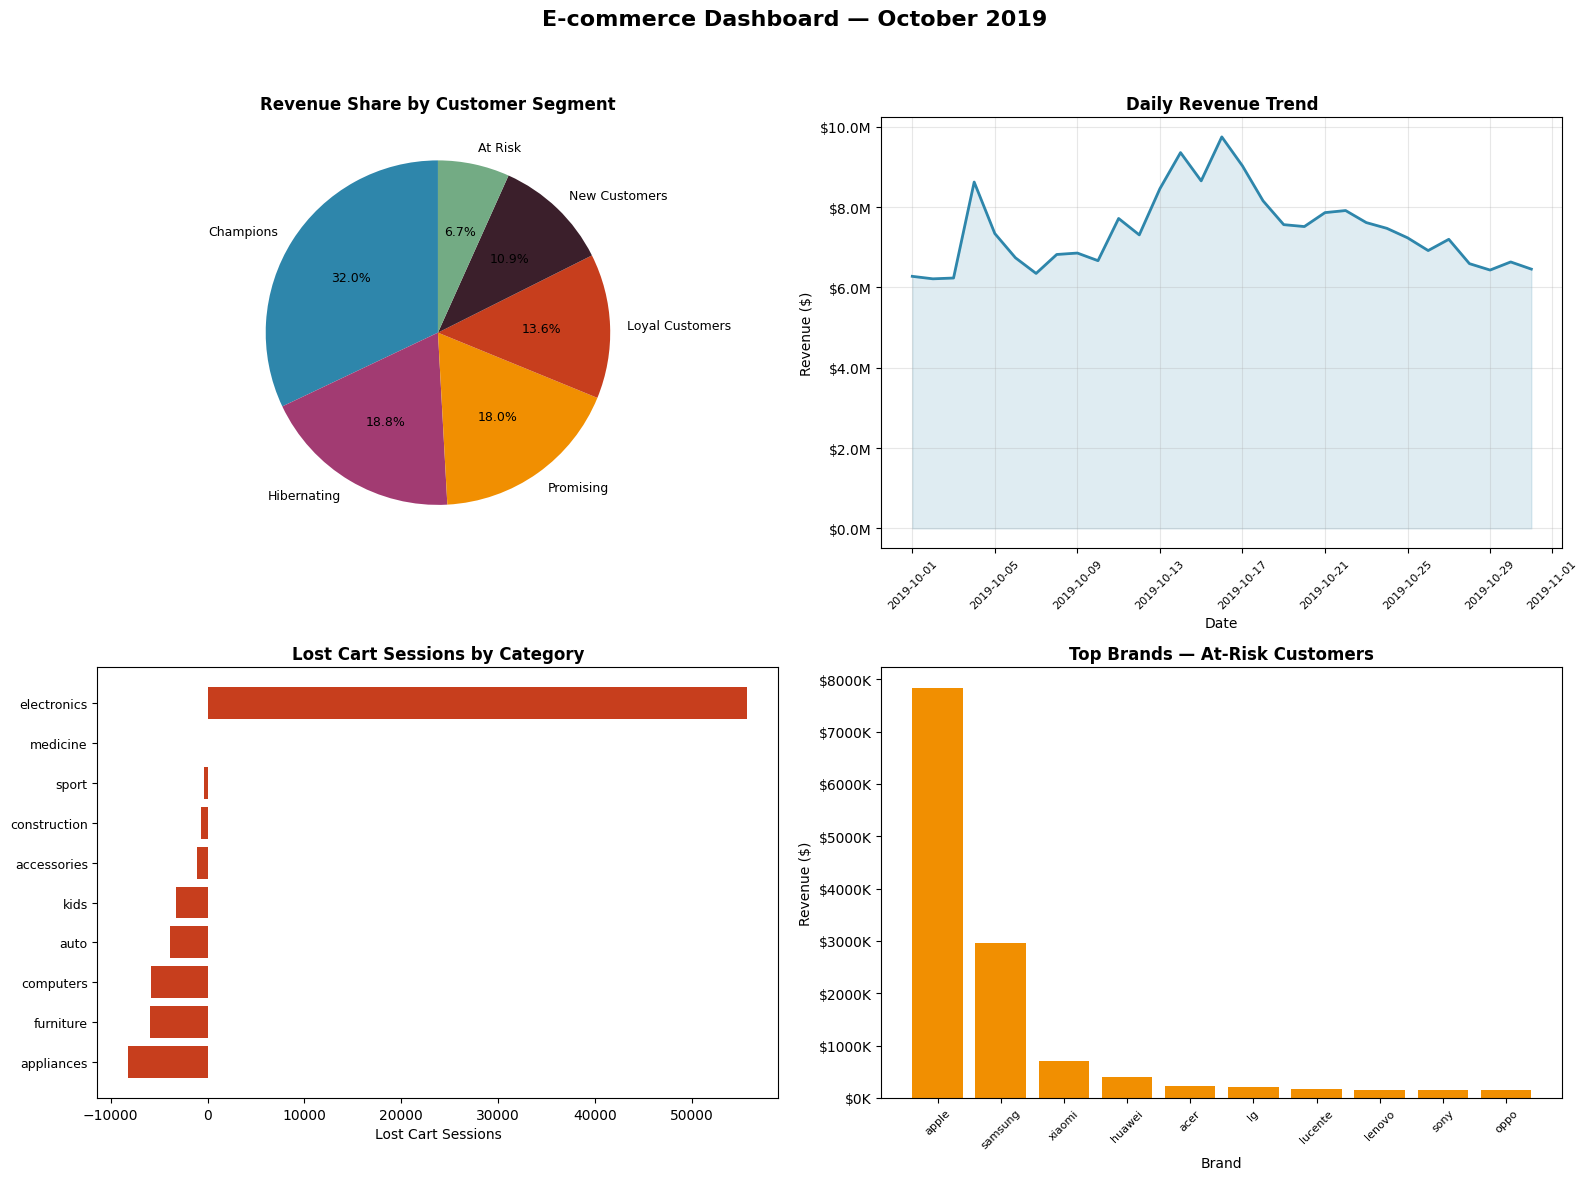

In [0]:
# 13. Inline dashboard — matplotlib version
#
# Databricks SQL visualisations (cells 9–12) only render inside the Databricks UI.
# This cell rebuilds the same four charts with matplotlib so the notebook is
# self-contained when viewed on GitHub or nbviewer.
#
# Chart encoding choices:
#   Pie   — revenue share: emphasises the Champions story (5.7% of customers,
#            32% of revenue). A bar chart shows the same numbers but the
#            disproportionality is less immediately visible.
#   Line  — daily revenue: time-series → line is the natural encoding.
#   Horiz bar — cart abandonment: long category labels → horizontal avoids
#               45° rotation that makes text hard to scan.
#   Vert bar — at-risk brands: brand names are shorter and fit vertically.

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

CATALOG = "workspace"
SCHEMA = "ecommerce"
spark.sql(f"USE {CATALOG}.{SCHEMA}")

# Pull from gold tables
segment_df = spark.sql("SELECT segment, customers, revenue, revenue_share_pct FROM gold_segment_summary ORDER BY revenue DESC").toPandas()
revenue_df = spark.sql("SELECT event_date, SUM(revenue) AS revenue FROM gold_funnel_daily GROUP BY event_date ORDER BY event_date").toPandas()
funnel_df  = spark.sql("""
  SELECT category_main, SUM(cart_sessions) - SUM(purchase_sessions) AS lost_cart_sessions
  FROM gold_funnel_daily GROUP BY category_main
  HAVING SUM(cart_sessions) > 100 ORDER BY lost_cart_sessions DESC LIMIT 10
""").toPandas()
brand_df   = spark.sql("""
  SELECT s.brand, ROUND(SUM(s.price), 2) AS revenue
  FROM silver_events s JOIN gold_rfm_customers c ON s.user_id = c.user_id
  WHERE s.event_type = 'purchase' AND c.segment = 'At Risk' AND s.brand <> 'unknown'
  GROUP BY s.brand ORDER BY revenue DESC LIMIT 10
""").toPandas()

seg_colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B', '#73AB84']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-commerce Dashboard — October 2019', fontsize=16, fontweight='bold')

# Chart 1: Revenue share by segment
# Key story: Champions = 5.7% of customers but 32% of revenue
ax1 = axes[0, 0]
ax1.pie(segment_df['revenue'], labels=segment_df['segment'], autopct='%1.1f%%',
        colors=seg_colors, startangle=90, textprops={'fontsize': 9})
ax1.set_title('Revenue Share by Customer Segment', fontsize=12, fontweight='bold')

# Chart 2: Daily revenue trend
ax2 = axes[0, 1]
ax2.plot(revenue_df['event_date'], revenue_df['revenue'], color='#2E86AB', linewidth=2)
ax2.fill_between(revenue_df['event_date'], revenue_df['revenue'], alpha=0.15, color='#2E86AB')
ax2.set_title('Daily Revenue Trend', fontsize=12, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Revenue ($)')
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax2.tick_params(axis='x', rotation=45, labelsize=8)
ax2.grid(True, alpha=0.3)

# Chart 3: Cart abandonment — electronics leads in absolute lost sessions
ax3 = axes[1, 0]
ax3.barh(funnel_df['category_main'][::-1], funnel_df['lost_cart_sessions'][::-1], color='#C73E1D')
ax3.set_title('Lost Cart Sessions by Category', fontsize=12, fontweight='bold')
ax3.set_xlabel('Lost Cart Sessions')
ax3.tick_params(axis='y', labelsize=9)

# Chart 4: Top brands for At-Risk customers — use in win-back email
ax4 = axes[1, 1]
ax4.bar(brand_df['brand'], brand_df['revenue'], color='#F18F01')
ax4.set_title('Top Brands — At-Risk Customers', fontsize=12, fontweight='bold')
ax4.set_xlabel('Brand')
ax4.set_ylabel('Revenue ($)')
ax4.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
ax4.tick_params(axis='x', rotation=45, labelsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


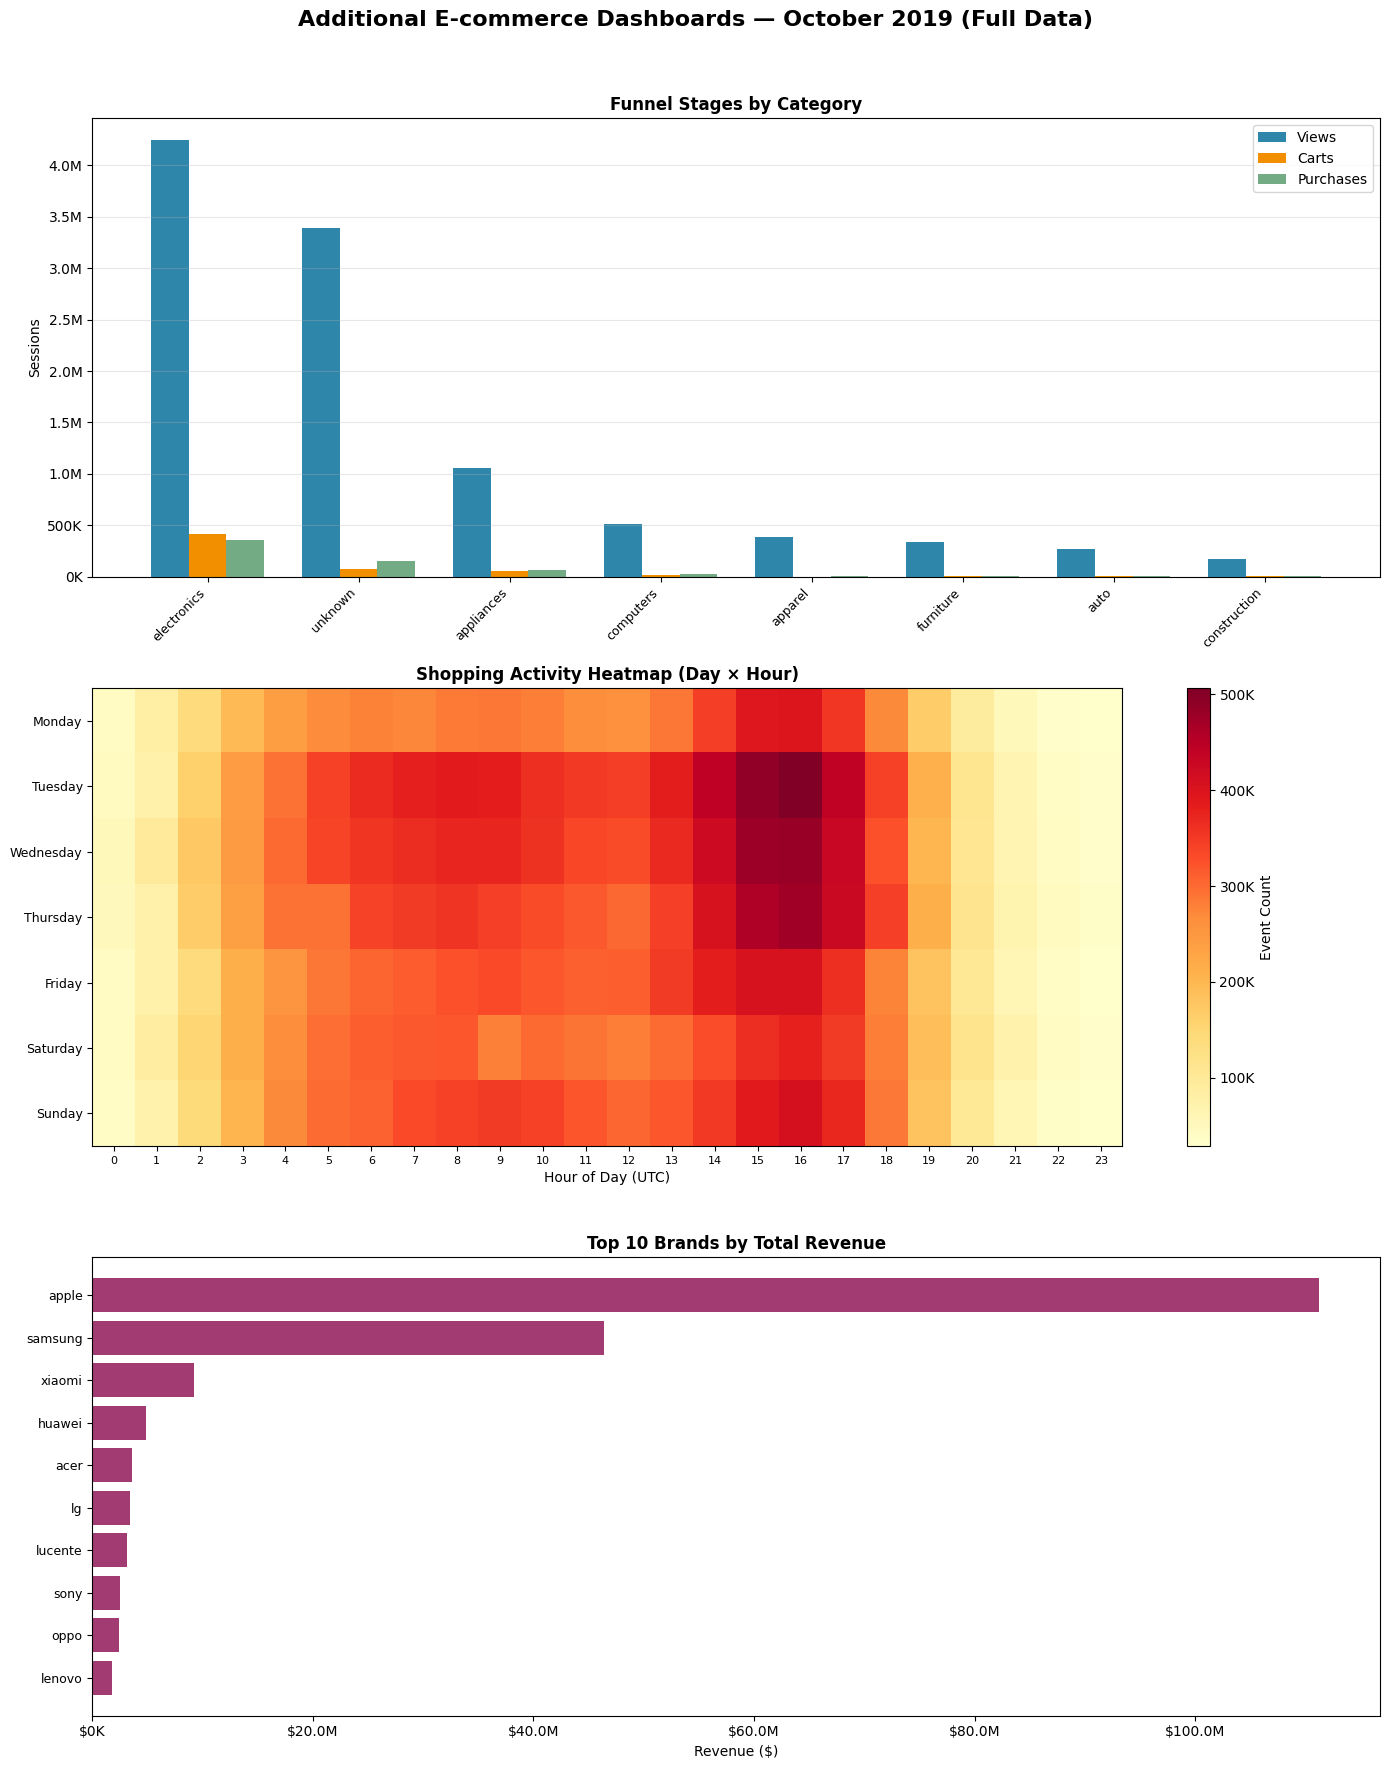

In [0]:
# 14. Additional charts — funnel by category, hourly heatmap, top brands
#
# The first dashboard (cell 13) answered the three headline questions.
# These three charts came out of follow-up questions I had while looking at those results:
#
#   1. Funnel stages by category (grouped bar)
#      The cell 11 chart showed which category loses the most cart sessions in absolute terms.
#      But I wanted to see the full view→cart→purchase shape per category side-by-side,
#      because a category with low absolute abandonment might still have a terrible cart-to-purchase rate.
#
#   2. Hourly shopping heatmap (day × hour)
#      Revenue and conversion vary by time of day — knowing WHEN users are most active
#      is useful for scheduling push notifications and email send times.
#      A heatmap is the right encoding here: two categorical axes with a continuous value.
#
#   3. Top 10 brands by total revenue (horizontal bar)
#      Cell 12 only showed brands for the At-Risk segment. I wanted the overall brand ranking
#      to check whether the At-Risk brands (samsung, apple, xiaomi) are also the top brands
#      site-wide — which would mean the win-back email isn't just targeting niche preferences.

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

spark.sql("USE workspace.ecommerce")

# --- Chart 1 data: funnel stages by category (top 8 by views) ---
funnel_stages = spark.sql("""
  SELECT category_main,
         SUM(view_sessions)     AS views,
         SUM(cart_sessions)     AS carts,
         SUM(purchase_sessions) AS purchases
  FROM gold_funnel_daily
  GROUP BY category_main
  ORDER BY views DESC
  LIMIT 8
""").toPandas()

# --- Chart 2 data: hourly activity heatmap ---
hourly = spark.sql("""
  SELECT
    DATE_FORMAT(event_ts, 'EEEE') AS day_of_week,
    HOUR(event_ts)                 AS hour,
    COUNT(*)                       AS events
  FROM silver_events
  GROUP BY DATE_FORMAT(event_ts, 'EEEE'), HOUR(event_ts)
""").toPandas()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly['day_of_week'] = pd.Categorical(hourly['day_of_week'], categories=day_order, ordered=True)
heatmap_data = hourly.pivot(index='day_of_week', columns='hour', values='events').reindex(index=day_order).fillna(0)

# --- Chart 3 data: top 10 brands by total revenue ---
top_brands = spark.sql("""
  SELECT brand, ROUND(SUM(price), 2) AS revenue
  FROM silver_events
  WHERE event_type = 'purchase' AND brand <> 'unknown'
  GROUP BY brand
  ORDER BY revenue DESC
  LIMIT 10
""").toPandas()

# --- Plot 3 × 1 grid ---
fig, axes = plt.subplots(3, 1, figsize=(14, 18))
fig.suptitle('Additional E-commerce Dashboards — October 2019 (Full Data)', fontsize=16, fontweight='bold')

# Chart 1: Funnel stages by category (grouped bar)
ax1 = axes[0]
x = np.arange(len(funnel_stages))
width = 0.25
ax1.bar(x - width, funnel_stages['views'],     width, label='Views',     color='#2E86AB')
ax1.bar(x,         funnel_stages['carts'],     width, label='Carts',     color='#F18F01')
ax1.bar(x + width, funnel_stages['purchases'], width, label='Purchases', color='#73AB84')
ax1.set_xticks(x)
ax1.set_xticklabels(funnel_stages['category_main'], rotation=45, ha='right', fontsize=9)
ax1.set_title('Funnel Stages by Category', fontsize=12, fontweight='bold')
ax1.set_ylabel('Sessions')
ax1.legend()
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1e3:.0f}K'))
ax1.grid(True, alpha=0.3, axis='y')

# Chart 2: Hourly shopping heatmap
ax2 = axes[1]
im = ax2.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto')
ax2.set_xticks(range(24))
ax2.set_xticklabels(range(24), fontsize=8)
ax2.set_yticks(range(7))
ax2.set_yticklabels(day_order, fontsize=9)
ax2.set_xlabel('Hour of Day (UTC)')
ax2.set_title('Shopping Activity Heatmap (Day × Hour)', fontsize=12, fontweight='bold')
cbar = plt.colorbar(im, ax=ax2, label='Event Count')
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1e3:.0f}K'))

# Chart 3: Top 10 brands by total revenue (horizontal bar)
ax3 = axes[2]
ax3.barh(top_brands['brand'][::-1], top_brands['revenue'][::-1], color='#A23B72')
ax3.set_title('Top 10 Brands by Total Revenue', fontsize=12, fontweight='bold')
ax3.set_xlabel('Revenue ($)')
ax3.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'${v/1e6:.1f}M' if v >= 1e6 else f'${v/1e3:.0f}K'))
ax3.tick_params(axis='y', labelsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Business Recommendations

All numbers below come directly from the Gold tables computed above.

---

### 1. Win-back campaign: At-Risk customers

**Who:** 9,345 customers (2.7% of all buyers) who averaged 4.1 orders/month but haven't purchased in ~22 days.
**Revenue at stake:** $15.4M — 6.7% of total revenue. Their average spend is $1,653, nearly 5× the Hibernating segment's $334.
**Action:** personalised email featuring their top brands (samsung, apple, xiaomi dominate by revenue). A 10% re-activation rate would recover ~$1.5M at minimal cost.
**Why this segment first, not Hibernating:** At-Risk customers have demonstrated high spending willingness. Hibernating is 37% of buyers but low spend per head — you'd need to move 10× more customers to generate the same revenue lift.

---

### 2. Fix the electronics funnel leak

**The problem:** 55,724 electronics sessions added to cart but never purchased — the single largest abandonment source in absolute terms. Abandonment rate: 13.5%.
**Likely causes:** high average ticket (electronics is the top-revenue category), lack of financing options, or competitor price-checking at checkout.
**What to test:**
  - (a) Show BNPL / instalment options on the cart page
  - (b) Trigger a 24-hour "your cart is waiting" email for abandoned electronics carts
  - (c) Display a price-match badge at checkout
**Why electronics over furniture** (furniture has a 364% "abandonment" rate, which is actually a cross-session purchase artifact): furniture has ~6K absolute lost sessions vs electronics' 55K — even a modest 5% recovery on electronics outweighs fixing furniture entirely.

---

### 3. Protect the Champions segment

**Who:** 19,807 customers — only 5.7% of all buyers.
**Revenue:** $73.7M — **32% of total revenue**. Average spend $3,720, avg 7.8 orders, last purchase just ~5 days ago.
**Risk:** Champions are a concentration risk. If they churn to a competitor, a third of revenue disappears with them — and the data gives no early-warning signal in a single month snapshot.
**Action:** introduce early access, a dedicated support tier, or a loyalty programme *before* churn signals appear. Retention is cheaper than re-acquisition at this spend level.

---

### Limitations and next steps

- **One month of data:** seasonality is not captured. October may not be representative — repeat with full Q4 data to validate segment stability.
- **Rule-based RFM:** segment boundaries are hand-tuned. A logical next step is K-Means clustering on (R, F, M) to check whether data-driven clusters match these intuitive labels.
- **No causal inference:** we can see *that* At-Risk customers churn, but not *why*. Linking to customer service tickets or NPS scores would sharpen the intervention.
- **Scheduling:** this notebook should run as a nightly Databricks Job on a rolling 30-day window so segment assignments stay current.
